# HW5
DSCI 552

Name: Ruikun Zhang
GitHub Username: XOBECIUJ
USC ID: 6347-9436-32

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

## 1. Decision Trees as Interpretable Models
### (a) Download data

In [2]:
df = pd.read_csv('../data/diagnosis.data', sep='\t', encoding='utf-16', header=None)
df.columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains',
              'burning_urethra', 'inflammation', 'nephritis']

# temperature uses comma as decimal point
df['temperature'] = df['temperature'].str.replace(',', '.').astype(float)
for c in df.columns[1:]:
    df[c] = (df[c] == 'yes').astype(int)

df.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


there are 2 labels (inflammation of urinary bladder, nephritis of renal pelvis origin). I combine them into one label with 4 classes so one tree can predict both, e.g. I1_N0 means inflammation = yes, nephritis = no.

In [3]:
X = df.iloc[:, :6]
y = 'I' + df['inflammation'].astype(str) + '_N' + df['nephritis'].astype(str)
y.value_counts()

I1_N0    40
I0_N1    31
I0_N0    30
I1_N1    19
Name: count, dtype: int64

### (b) Decision tree on the whole data set

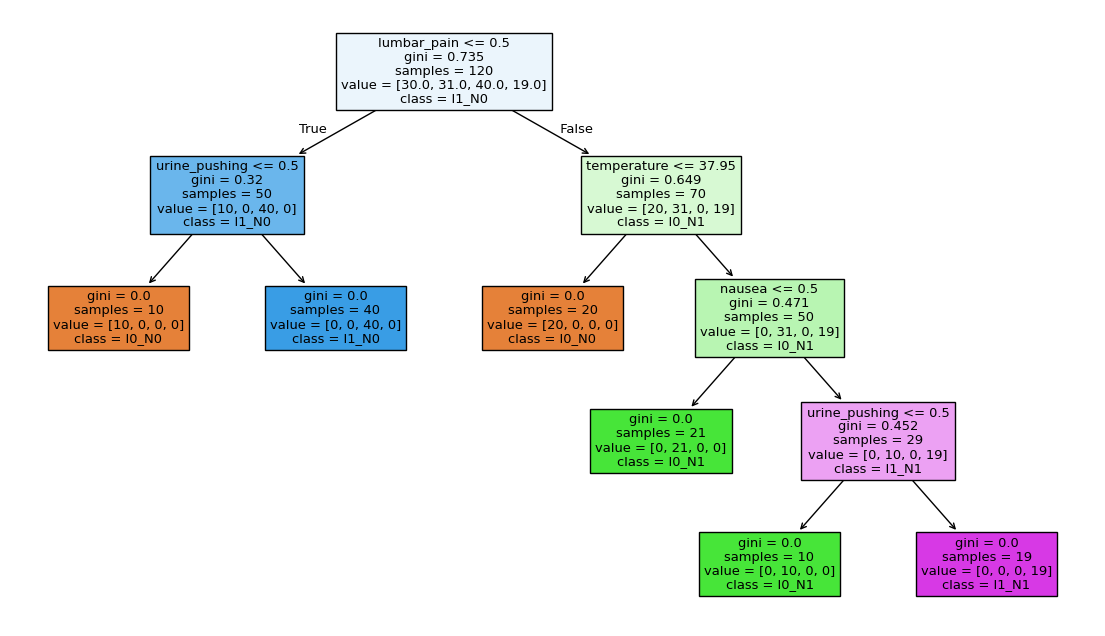

In [4]:
tree = DecisionTreeClassifier(random_state=1)
tree.fit(X, y)

plt.figure(figsize=(14, 8))
plot_tree(tree, feature_names=list(X.columns), class_names=list(tree.classes_), filled=True)
plt.show()

### (c) IF-THEN rules

In [5]:
print(export_text(tree, feature_names=list(X.columns)))

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: I0_N0
|   |--- urine_pushing >  0.50
|   |   |--- class: I1_N0
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: I0_N0
|   |--- temperature >  37.95
|   |   |--- nausea <= 0.50
|   |   |   |--- class: I0_N1
|   |   |--- nausea >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: I0_N1
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: I1_N1



binary features: <= 0.5 means no, > 0.5 means yes.

1. IF lumbar_pain = no AND urine_pushing = no THEN inflammation = no, nephritis = no
2. IF lumbar_pain = no AND urine_pushing = yes THEN inflammation = yes, nephritis = no
3. IF lumbar_pain = yes AND temperature <= 37.95 THEN inflammation = no, nephritis = no
4. IF lumbar_pain = yes AND temperature > 37.95 AND nausea = no THEN inflammation = no, nephritis = yes
5. IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no THEN inflammation = no, nephritis = yes
6. IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes THEN inflammation = yes, nephritis = yes

### (d) Cost-complexity pruning

In [6]:
path = tree.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
cv_acc = []
n_leaves = []
for a in alphas:
    m = DecisionTreeClassifier(random_state=1, ccp_alpha=a)
    cv_acc.append(cross_val_score(m, X, y, cv=skf).mean())
    n_leaves.append(m.fit(X, y).get_n_leaves())

pd.DataFrame({'alpha': alphas, 'leaves': n_leaves, 'cv accuracy': cv_acc})

,alpha,leaves,cv accuracy
0,0.000000,6,0.975000
1,0.098167,4,0.808333
2,0.133333,3,0.733333
3,0.182000,2,0.658333
4,0.222917,1,0.483333


best alpha: 0.0


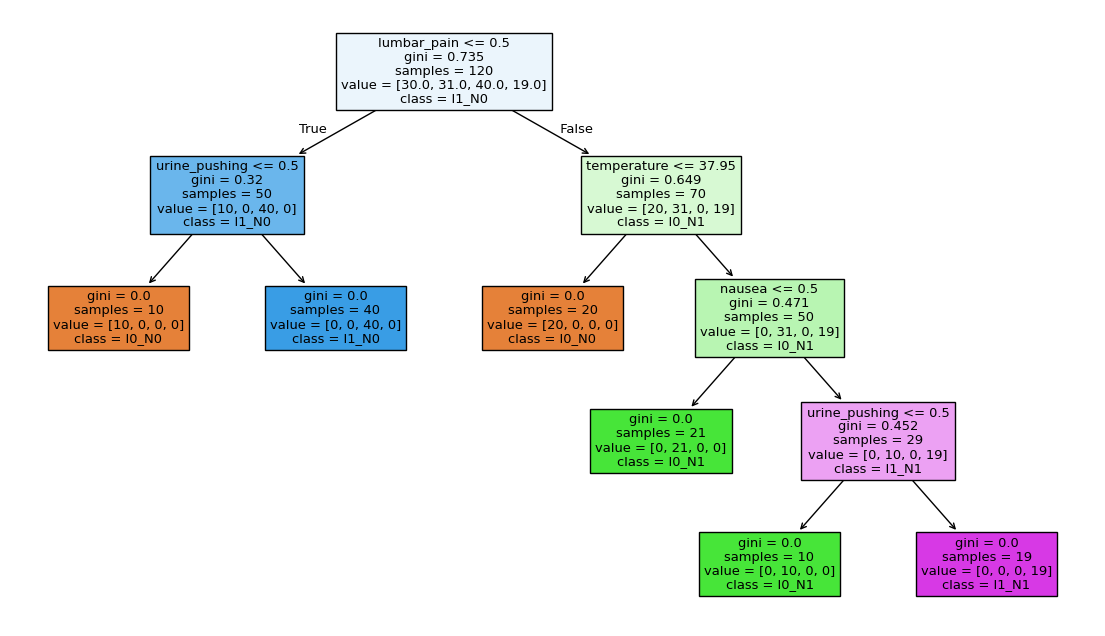

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: I0_N0
|   |--- urine_pushing >  0.50
|   |   |--- class: I1_N0
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: I0_N0
|   |--- temperature >  37.95
|   |   |--- nausea <= 0.50
|   |   |   |--- class: I0_N1
|   |   |--- nausea >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: I0_N1
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: I1_N1



In [7]:
best_alpha = alphas[np.argmax(cv_acc)]
print('best alpha:', best_alpha)

pruned = DecisionTreeClassifier(random_state=1, ccp_alpha=best_alpha)
pruned.fit(X, y)

plt.figure(figsize=(14, 8))
plot_tree(pruned, feature_names=list(X.columns), class_names=list(pruned.classes_), filled=True)
plt.show()
print(export_text(pruned, feature_names=list(X.columns)))

CV accuracy is highest at alpha = 0. for every alpha > 0 the tree loses leaves but accuracy drops a lot (0.975 -> 0.81 or lower), so pruning cannot remove any node without hurting the result. the tree with 6 leaves is already the minimal tree.

rule 4 and 5 give the same result, so they can be merged. final rules:

1. IF lumbar_pain = no AND urine_pushing = no THEN inflammation = no, nephritis = no
2. IF lumbar_pain = no AND urine_pushing = yes THEN inflammation = yes, nephritis = no
3. IF lumbar_pain = yes AND temperature <= 37.95 THEN inflammation = no, nephritis = no
4. IF lumbar_pain = yes AND temperature > 37.95 AND (nausea = no OR urine_pushing = no) THEN inflammation = no, nephritis = yes
5. IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes THEN inflammation = yes, nephritis = yes

## 2. The LASSO and Boosting for Regression
### (a) Download data, first 1495 rows as train

In [8]:
names = []
for line in open('../data/communities.names'):
    if line.startswith('@attribute'):
        names.append(line.split()[1])

crime = pd.read_csv('../data/communities.data', header=None, names=names, na_values='?')
crime.shape

(1994, 128)

### (b) Missing values and nonpredictive features

the description says the first 5 attributes (state, county, community, communityname, fold) are not predictive, so I drop them. missing values are filled with the median of each column in the training set.

In [9]:
crime = crime.drop(columns=['state', 'county', 'community', 'communityname', 'fold'])
print(crime.shape)
print('columns with missing values:', (crime.isna().sum() > 0).sum())

median = crime.iloc[:1495].median()
crime = crime.fillna(median)

train = crime.iloc[:1495]
test = crime.iloc[1495:]
X_train = train.drop(columns='ViolentCrimesPerPop')
y_train = train['ViolentCrimesPerPop']
X_test = test.drop(columns='ViolentCrimesPerPop')
y_test = test['ViolentCrimesPerPop']
print(X_train.shape, X_test.shape)

(1994, 123)
columns with missing values: 23
(1495, 122) (499, 122)


### (c) Correlation matrix

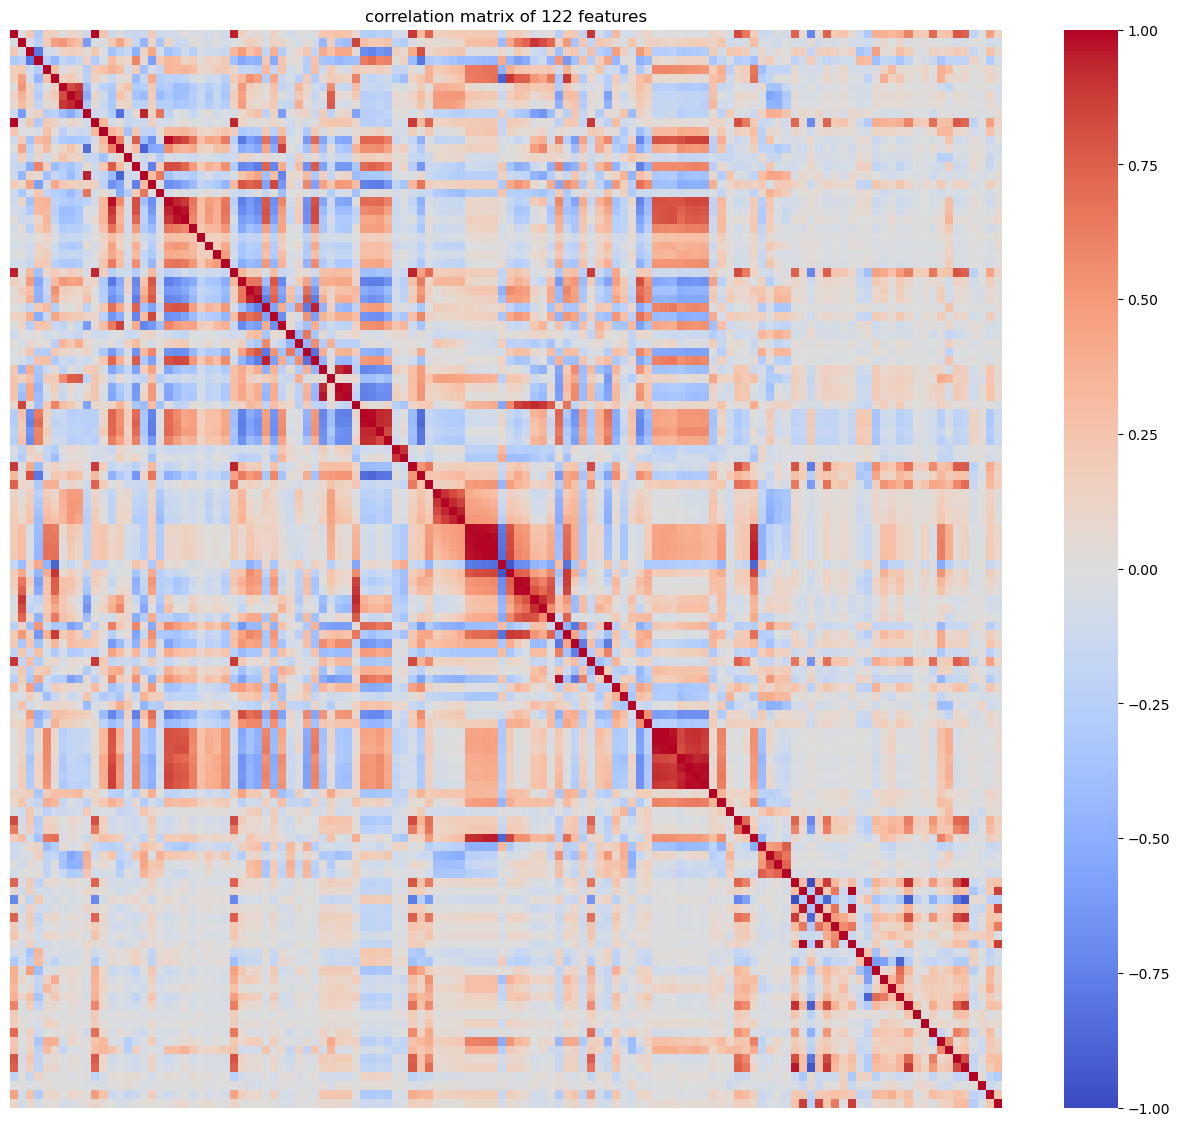

In [10]:
features = crime.drop(columns='ViolentCrimesPerPop')
plt.figure(figsize=(16, 14))
sns.heatmap(features.corr(), cmap='coolwarm', vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title('correlation matrix of 122 features')
plt.show()

### (d) Coefficient of Variation

In [11]:
cv = features.std() / features.mean()
cv.sort_values(ascending=False)

PctPolicAsian          5.447835
NumStreet              4.407702
NumInShelters          3.485481
NumIlleg               2.994196
NumImmig               2.900497
                         ...   
NumKindsDrugsSeiz      0.143227
RacialMatchCommPol     0.126902
LemasPctPolicOnPatr    0.117807
PctPolicWhite          0.117726
LemasSwFTFieldOps      0.057515
Length: 122, dtype: float64

### (e) Top floor(sqrt(128)) = 11 features by CV

['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


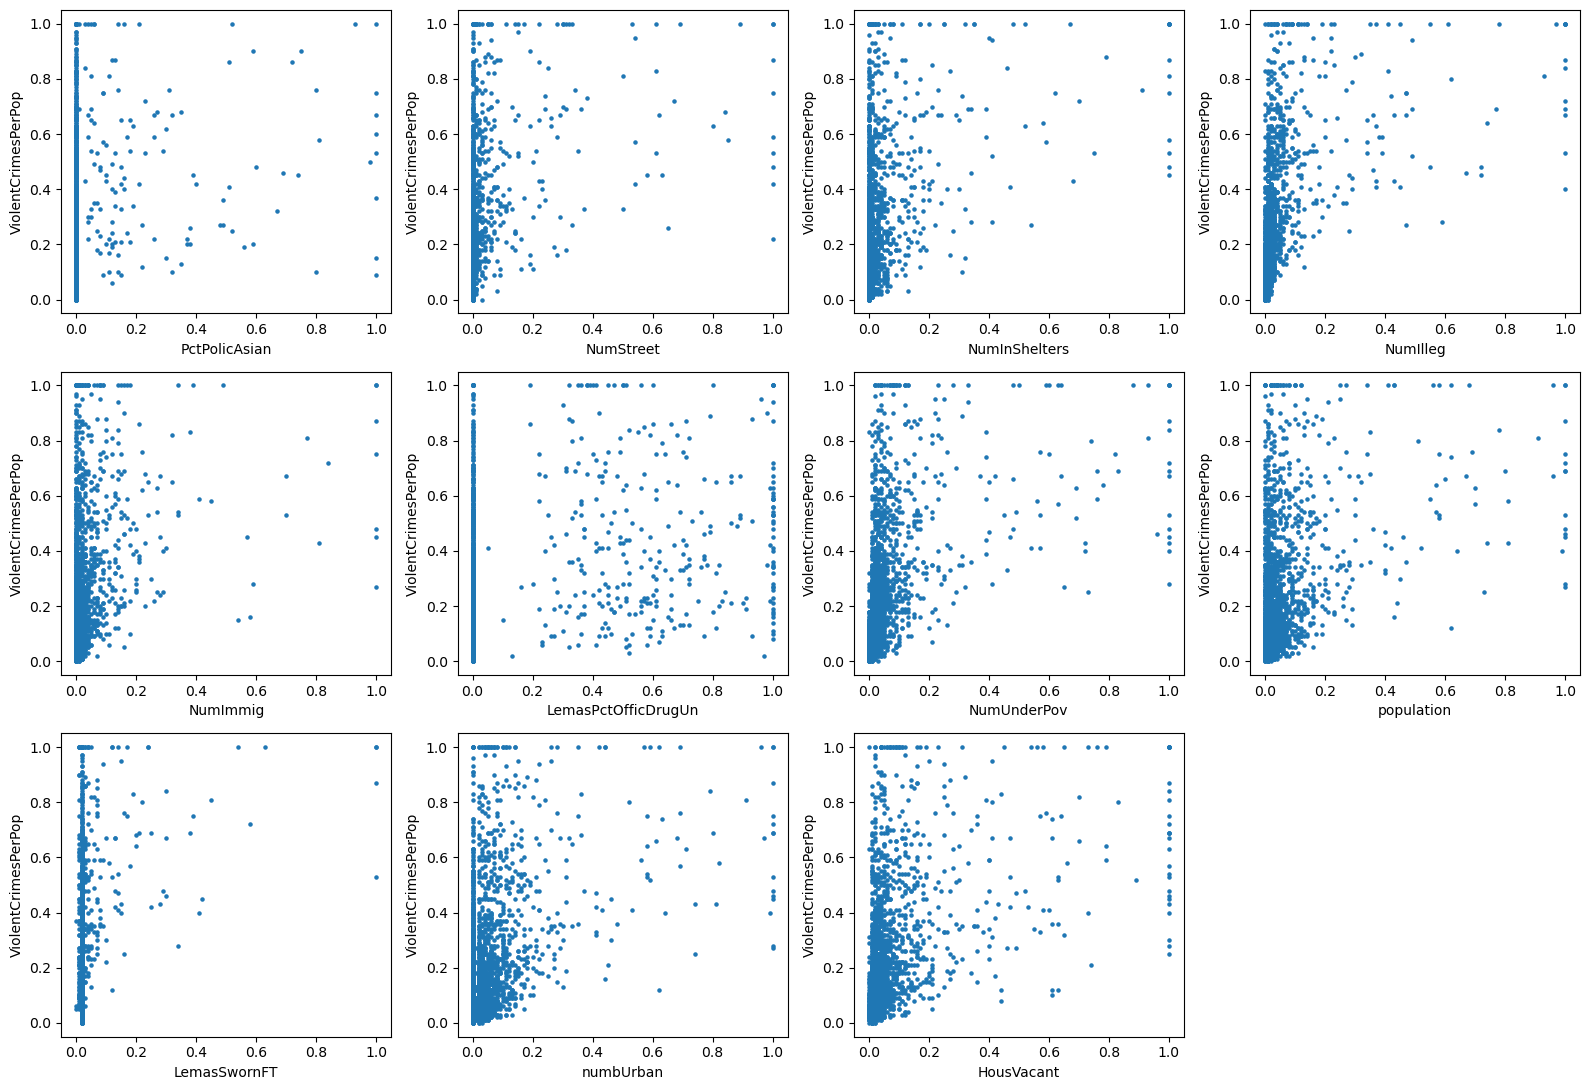

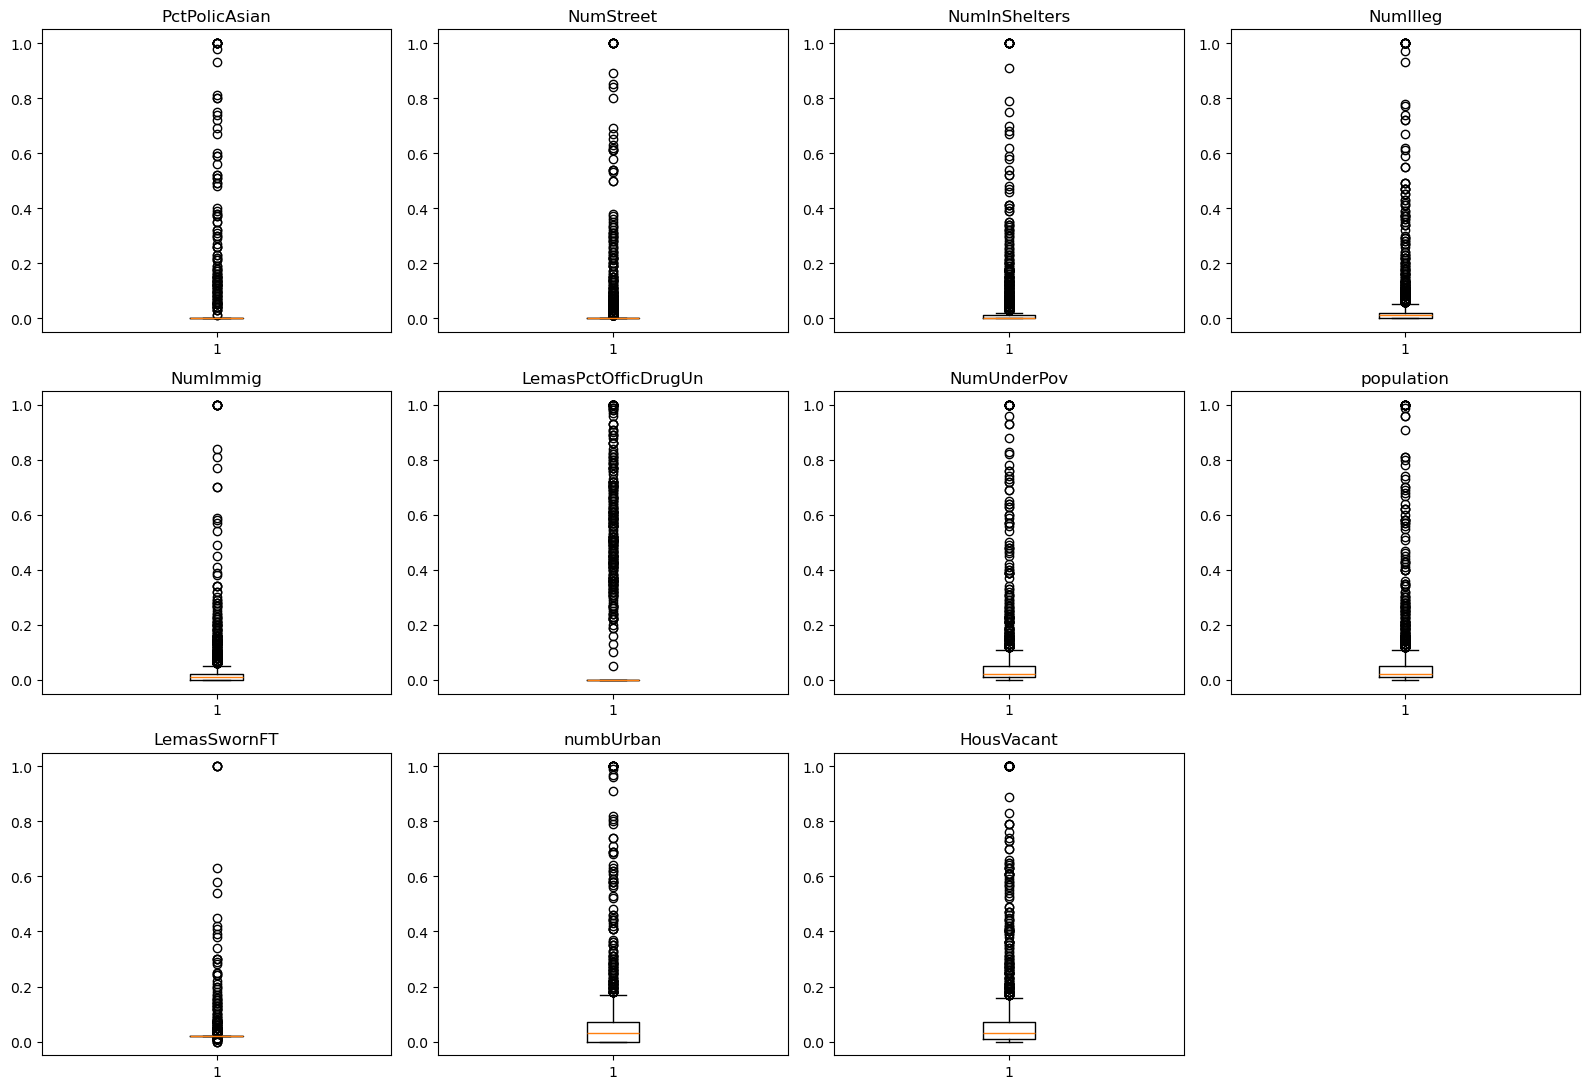

In [12]:
k = int(np.floor(np.sqrt(128)))
top = cv.sort_values(ascending=False).index[:k]
print(list(top))

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()
for i in range(k):
    axes[i].scatter(crime[top[i]], crime['ViolentCrimesPerPop'], s=5)
    axes[i].set_xlabel(top[i])
    axes[i].set_ylabel('ViolentCrimesPerPop')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()
for i in range(k):
    axes[i].boxplot(crime[top[i]])
    axes[i].set_title(top[i])
axes[-1].axis('off')
plt.tight_layout()
plt.show()

no. most of these features are counts (NumStreet, NumIlleg, population ...), almost all points are close to 0 and only few points are large, so the scatter plots are very squeezed. some of them (like NumIlleg, NumUnderPov) show a weak upward trend, but a scatter plot only shows one feature at a time and does not give any p-value. to know if a feature is significant we need to fit a model and do a test, we cannot decide it just by the plots.

### (f) Linear model (least squares)

In [13]:
ols = LinearRegression()
ols.fit(X_train, y_train)
print('OLS test MSE:', mean_squared_error(y_test, ols.predict(X_test)))

OLS test MSE: 0.01796621542606732


### (g) Ridge regression, lambda by CV

In [14]:
kf = KFold(n_splits=10, shuffle=True, random_state=1)

ridge = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=kf)
ridge.fit(X_train, y_train)
print('best lambda:', ridge.alpha_)
print('Ridge test MSE:', mean_squared_error(y_test, ridge.predict(X_test)))

best lambda: 2.1544346900318843
Ridge test MSE: 0.017525046262751972


### (h) LASSO, lambda by CV

In [15]:
lasso = LassoCV(cv=kf, random_state=1, max_iter=100000)
lasso.fit(X_train, y_train)
print('best lambda:', lasso.alpha_)
print('LASSO test MSE:', mean_squared_error(y_test, lasso.predict(X_test)))

selected = X_train.columns[lasso.coef_ != 0]
print(len(selected), 'variables selected:')
print(list(selected))

best lambda: 7.641712569306599e-05
LASSO test MSE: 0.017695604682563336
79 variables selected:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMomYoungKids', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRe

standardized features:

In [16]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lasso_s = LassoCV(cv=kf, random_state=1, max_iter=100000)
lasso_s.fit(X_train_s, y_train)
print('best lambda:', lasso_s.alpha_)
print('LASSO (standardized) test MSE:', mean_squared_error(y_test, lasso_s.predict(X_test_s)))

selected_s = X_train.columns[lasso_s.coef_ != 0]
print(len(selected_s), 'variables selected:')
print(list(selected_s))

best lambda: 0.0006189604623293166
LASSO (standardized) test MSE: 0.01772699141978069
76 variables selected:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc'

test MSE without standardization is 0.01770, with standardization is 0.01773. they are almost the same. the reason is all features in this data set are already normalized to 0-1, so standardizing does not change the scale too much. the selected variables are also mostly the same (79 vs 76).

### (i) PCR, M by CV

best M: 96


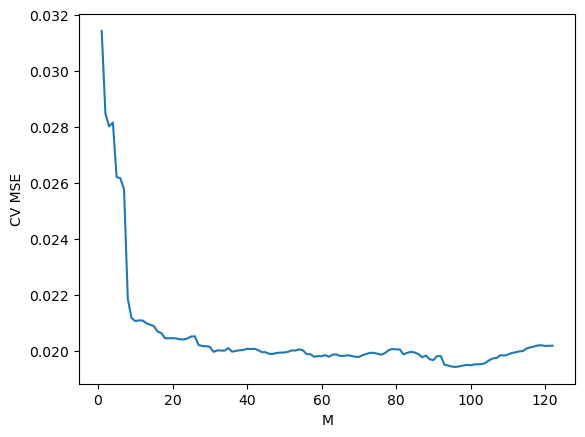

PCR test MSE: 0.018324576336397797


In [17]:
pcr_mse = []
for M in range(1, X_train.shape[1] + 1):
    pcr = make_pipeline(StandardScaler(), PCA(n_components=M), LinearRegression())
    score = cross_val_score(pcr, X_train, y_train, cv=kf, scoring='neg_mean_squared_error')
    pcr_mse.append(-score.mean())

best_M = np.argmin(pcr_mse) + 1
print('best M:', best_M)

plt.plot(range(1, X_train.shape[1] + 1), pcr_mse)
plt.xlabel('M')
plt.ylabel('CV MSE')
plt.show()

pcr = make_pipeline(StandardScaler(), PCA(n_components=best_M), LinearRegression())
pcr.fit(X_train, y_train)
print('PCR test MSE:', mean_squared_error(y_test, pcr.predict(X_test)))

### (j) L1 penalized boosting tree (XGBoost), alpha by CV

In [18]:
xgb = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=1)
params = {'reg_alpha': [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]}

grid = GridSearchCV(xgb, params, cv=kf, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)
print('best alpha:', grid.best_params_['reg_alpha'])
print('XGBoost test MSE:', mean_squared_error(y_test, grid.predict(X_test)))

best alpha: 2
XGBoost test MSE: 0.01605935869029616
